In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src.engine import *
from src.solvers.simulated_annealing import *
from src.visualizer import *

import matplotlib.pyplot as plt

In [3]:
trucks = [
   Truck("T1", 10, 20, 5, 200),
   Truck("T2", 8, 12, 4, 150),
   Truck("T3", 6, 10, 3, 100),
]

pkgs = [
   Package("S1", 1, 1, 1, 50, 2, False, 1),
   Package("S2", 1, 2, 1, 45, 3, False, 3),
   Package("S3", 2, 1, 1, 40, 2, True, 2),
   Package("S4", 1, 1, 2, 35, 1, False, 4),
   Package("S5", 2, 2, 1, 55, 4, False, 1),
   
   Package("M1", 3, 4, 2, 80, 10, False, 5),
   Package("M2", 2, 3, 2, 70, 8, True, 2),
   Package("M3", 4, 3, 1, 65, 12, False, 3),
   Package("M4", 3, 3, 3, 90, 15, False, 6),
   Package("M5", 2, 4, 2, 75, 9, False, 1),
   Package("M6", 3, 2, 2, 60, 11, True, 4),
   Package("M7", 4, 2, 3, 85, 14, False, 2),
   
   Package("L1", 5, 6, 3, 120, 25, False, 7),
   Package("L2", 4, 5, 2, 100, 20, False, 3),
   Package("L3", 6, 4, 2, 110, 22, True, 5),
   Package("L4", 5, 5, 3, 130, 30, False, 2),
   Package("L5", 4, 4, 4, 95, 18, False, 4),
   
   Package("H1", 3, 3, 2, 140, 35, False, 1),
   Package("H2", 2, 2, 2, 105, 28, False, 6),
   
   Package("B1", 6, 8, 3, 30, 40, False, 7),
   Package("B2", 5, 7, 4, 25, 35, False, 5),
   
   Package("F1", 2, 3, 1, 115, 6, True, 1),
   Package("F2", 3, 2, 2, 100, 7, True, 1),
]

init_state = State(pkgs, trucks, init="random_feasible")

In [4]:
draw_state(init_state)

In [53]:
obj = MaxValueObjective()
schedule = LogarithmicSchedule(200)

solver_sa = SimulatedAnnealing(obj, schedule, max_iterations=20000)
results = solver_sa.solve(init_state)

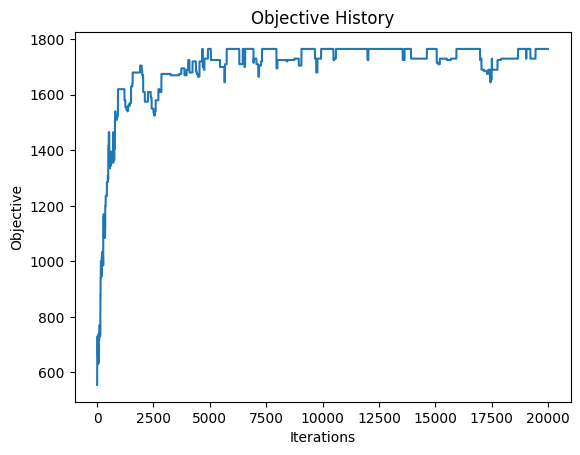

In [54]:
plt.plot(results.objective_history)
plt.title('Objective History')
plt.xlabel('Iterations')
plt.ylabel('Objective')
plt.show()

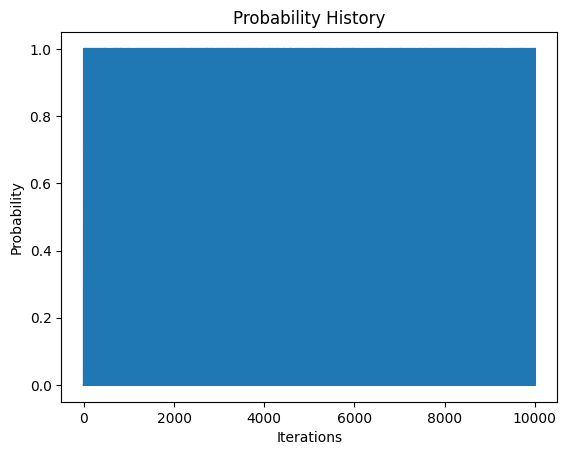

In [50]:
plt.plot(results.metadata['probability_history'])
plt.title('Probability History')
plt.xlabel('Iterations')
plt.ylabel('Probability')
plt.show()

In [60]:
print(results)

Solver: SimulatedAnnealing
Objective Function: MaxValueObjective
--------------------------------------------------
Runtime: 4.743s
Total Iterations: 20,000
Initial Objective: 555.00
Final Objective: 1765.00
--------------------------------------------------
Probability History  : [20000 values]


In [56]:
draw_state(results.final_state)